In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# PRNG from last HW

In [2]:
class LinearCongruentialGenerator:
    def __init__(self, x0=69069, a=25214903917, b=11, M=2**48):
        """ initialized using the parameters used by Unix drand48()"""
        self.x_now = x0
        self.a = a
        self.b = b
        self.M = M


    def random(self):
        self.x_now = (self.a * self.x_now + self.b) % self.M
        return self.x_now / self.M


class FibonacciGenerator:
    def __init__(self, x0=69069, lag1=607, lag2=273):
        """
        initalized using the parameters used by Go's (Google's C++ replacement) random number generator.eca
        these parameters yield a period of 2^669.
        """
        self.lag1 = lag1
        self.lag2 = lag2

        initializer = LinearCongruentialGenerator(x0=x0)
        self.state = [initializer.random() for _ in range(lag1)]


    def random(self):
        x_now = (self.state[-self.lag1] + self.state[-self.lag2]) % 1

        self.state.append(x_now)
        self.state.pop(0)

        return x_now


random = FibonacciGenerator()

# Question 1

Look how amazing the polynomial I chose is!!!


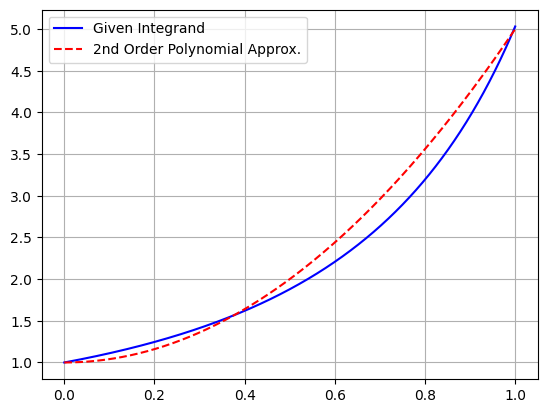

Crude:         mean=2.217789, var=1.149754
Imp. Sampling: mean=2.217325, var=0.018163


In [3]:
# parameters
n_samples = 100_000

a = 0
b = 1

# functions
def h_of_x(x):
    numer = np.exp(x)
    denom = np.cos(x)
    return numer / denom


def f_star_of_x(x):
    return (3/7 * (4 * x**2 + 1))


# crude MC
def crude_sample():
    return (a + random.random() * (b - a))


crude_xs = np.array([crude_sample() for _ in range(n_samples)])
crude_gs = (b - a) * h_of_x(crude_xs)

crude_mean = np.mean(crude_gs)
crude_var = np.var(crude_gs, ddof=1)


# importance sampling
alpha1 = 7 / 4
alpha2 = 7 / 3


def importance_sample():
    eta1 = random.random()
    eta2 = random.random()

    if eta1 <= (1 / alpha1):
        return (eta2)**(1/3)

    if (1 / alpha1) < eta1 <= (1 / alpha1 + 1 / alpha2):
        return eta2


importance_xs = np.array([importance_sample() for _ in range(n_samples)])
importance_g_stars = h_of_x(importance_xs) / f_star_of_x(importance_xs)

importance_mean = np.mean(importance_g_stars)
importance_var = np.var(importance_g_stars, ddof=1)


# results
xs = np.linspace(0, 1, 10000)
hs = h_of_x(xs)
fs = 7 / 3 * f_star_of_x(xs)

plt.plot(xs, hs, label="Given Integrand", color="b")
plt.plot(xs, fs, label="2nd Order Polynomial Approx.", color="r", ls="--")

plt.grid(which="both")
plt.legend()

plt.savefig("q1_integrand_vs_approx", dpi=600)

print("Look how amazing the polynomial I chose is!!!")
plt.show()

# means and vars
print(f"{"Crude:":<14} mean={crude_mean:5f}, var={crude_var:5f}")
print(f"Imp. Sampling: mean={importance_mean:5f}, var={importance_var:5f}")

# Question 2

In [4]:
# parameters
a = 0
b = 1

m_strata = 10
list_of_n_samples = [100, 500, 1_000, 5_000, 10_000, 50_000, 100_000]


# functions
def h_of_x(x):
    return 1 / (1 + x**2)


def crude_sample():
    return (a + random.random() * (b - a))


# calc functions
def calc_crude_mean(n_samples):
    crude_xs = np.array([crude_sample() for _ in range(n_samples)])
    crude_gs = (b - a) * h_of_x(crude_xs)
    
    crude_mean = np.mean(crude_gs)
    crude_var = np.var(crude_gs, ddof=1)

    return crude_mean, crude_var


def calc_uniform_strata(n_samples):
    n_per_stratum = n_samples // m_strata
    strata_edges = np.linspace(a, b, m_strata + 1)
    h_m = 1.0 / m_strata

    strata_means = []
    strata_vars = []

    for m_idx in range(m_strata):
        a_m = strata_edges[m_idx]
        b_m = strata_edges[m_idx + 1]

        xs_m = np.array(
            [(a_m + random.random() * (b_m - a_m)) for _ in range(n_per_stratum)]
        )
        gs_m = h_of_x(xs_m)

        strata_means.append(np.mean(gs_m))
        strata_vars.append(np.var(gs_m, ddof=1))

    uniform_strat_mean = np.sum(h_m * np.array(strata_means))
    uniform_strat_var = np.sum(
        (h_m**2 * np.array(strata_vars)) / n_per_stratum
    )

    return uniform_strat_mean, uniform_strat_var


def calc_optimum_strata(n_samples):
    strata_edges = np.linspace(a, b, m_strata + 1)
    h_m = 1.0 / m_strata

    # precalc set to 20% bc you need 2 samples for var; lowest N=100 w/ m=10 strata
    n_precalc_total = int(0.20 * n_samples)
    n_precalc_per_stratum = n_precalc_total // m_strata

    n_precalc_total = n_precalc_per_stratum * m_strata
    n_calc_total = n_samples - n_precalc_total

    # begin precalc run
    precalc_samples = []
    precalc_vars = []

    for m_idx in range(m_strata):
        a_m, b_m = strata_edges[m_idx], strata_edges[m_idx + 1]
        
        xs_precalc = np.array(
            [(a_m + random.random() * (b_m - a_m)) for _ in range(n_precalc_per_stratum)]
        )
        gs_precalc = h_of_x(xs_precalc)

        precalc_samples.append(gs_precalc)
        precalc_vars.append(np.std(gs_precalc, ddof=1))

    precalc_vars = np.array(precalc_vars)

    # calc allocation
    denom = np.sum(h_m * precalc_vars)
    
    n_m_calc = ((h_m * precalc_vars) / denom) * n_calc_total
    n_m_calc = np.round(n_m_calc).astype(int)

    while np.sum(n_m_calc) != n_calc_total:
        diff = n_calc_total - np.sum(n_m_calc)
        
        if diff > 0:
            n_m_calc[np.argmin(n_m_calc)] += 1
            continue
            
        if diff < 0:
            n_m_calc[np.argmax(n_m_calc)] -= 1
            continue

    # begin calc run
    all_strata_samples = []

    for m_idx in range(m_strata):
        a_m, b_m = strata_edges[m_idx], strata_edges[m_idx + 1]
        n_calc = n_m_calc[m_idx]
        
        xs_calc = np.array(
            [(a_m + random.random() * (b_m - a_m)) for _ in range(n_calc)]
        )
        gs_calc = h_of_x(xs_calc)

        combined_samples = np.concatenate([precalc_samples[m_idx], gs_calc])
        all_strata_samples.append(combined_samples)

    # mean and var
    strata_means = [np.mean(strata_samples) for strata_samples in all_strata_samples]
    strata_vars = [np.var(strata_samples, ddof=1) for strata_samples in all_strata_samples]
    
    opt_strat_mean = np.sum(h_m * np.array(strata_means))
    
    # Standard stratified variance formula tracking actual total points per bin
    n_m_total = np.array([len(strata_samples) for strata_samples in all_strata_samples])
    opt_strat_var = np.sum((h_m**2 * np.array(strata_vars)) / n_m_total)

    return opt_strat_mean, opt_strat_var


# results
print(f"{'Method':<20} | {'Samples':<10} | {'Expected Value':<16} | {'Std. Error':<11} | {'Rel. Error':<12}")
print("-" * 80)

for n_samples in list_of_n_samples:
    mean, var = calc_crude_mean(n_samples)
    sem = np.sqrt(var) / np.sqrt(n_samples)
    rel_diff = sem / mean
    print(f"{'Standard':<20} | {n_samples:<10,} | {mean:<16.5f} | {sem:<10.5e} | {rel_diff:<12.5e}")
print("-" * 80)

for n_samples in list_of_n_samples:
    mean, var = calc_uniform_strata(n_samples)
    sem = np.sqrt(var) / np.sqrt(n_samples)
    rel_diff = sem / mean
    print(f"{'Uniform Stratified':<20} | {n_samples:<10,} | {mean:<16.5f} | {sem:<10.5e} | {rel_diff:<12.5e}")
print("-" * 80)

for n_samples in list_of_n_samples:
    mean, var = calc_optimum_strata(n_samples)
    sem = np.sqrt(var) / np.sqrt(n_samples)
    rel_diff = sem / mean
    print(f"{'Optimum Stratified':<20} | {n_samples:<10,} | {mean:<16.5f} | {sem:<10.5e} | {rel_diff:<12.5e}")
print("-" * 80)

Method               | Samples    | Expected Value   | Std. Error  | Rel. Error  
--------------------------------------------------------------------------------
Standard             | 100        | 0.79304          | 1.64083e-02 | 2.06904e-02 
Standard             | 500        | 0.79095          | 7.47991e-03 | 9.45687e-03 
Standard             | 1,000      | 0.78553          | 5.17515e-03 | 6.58813e-03 
Standard             | 5,000      | 0.78728          | 2.27753e-03 | 2.89290e-03 
Standard             | 10,000     | 0.78692          | 1.61802e-03 | 2.05614e-03 
Standard             | 50,000     | 0.78634          | 7.16932e-04 | 9.11738e-04 
Standard             | 100,000    | 0.78500          | 5.09448e-04 | 6.48980e-04 
--------------------------------------------------------------------------------
Uniform Stratified   | 100        | 0.78413          | 1.57642e-04 | 2.01040e-04 
Uniform Stratified   | 500        | 0.78518          | 3.08783e-05 | 3.93262e-05 
Uniform Stratified